In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Formatting the data

In [2]:
# Loading stock data from text files
path = "intraday US data/"
stocks = {"AAPL": pd.read_csv(path + "AAPL_5min.txt", sep=",", header=None),
          "CSCO": pd.read_csv(path + "CSCO_5min.txt", sep=",", header=None),
          "DOW": pd.read_csv(path + "DOW_5min.txt", sep=",", header=None),
          "GE": pd.read_csv(path + "GE_5min.txt", sep=",", header=None),
          "IBM": pd.read_csv(path + "IBM_5min.txt", sep=",", header=None),
          "JPM": pd.read_csv(path + "JPM_5min.txt", sep=",", header=None),
          "MSFT": pd.read_csv(path + "MSFT_5min.txt", sep=",", header=None),
          "NKE": pd.read_csv(path + "NKE_5min.txt", sep=",", header=None),
          "RTX": pd.read_csv(path + "RTX_5min.txt", sep=",", header=None)}

# Creating headers for the dataframes
for stock in stocks:
    stocks[stock].columns = ["Date&Time", "Open", "High", "Low", "Close", "Volume"]


In [3]:
# Remove open, high, and low columns
for stock in stocks:
    stocks[stock].drop(columns=["Open", "High", "Low"], inplace=True)


In [4]:
# Keep only stock prices that occured from 2010 to 2023
for stock in stocks:
    stocks[stock] = stocks[stock][(stocks[stock]["Date&Time"] >= "2010-01-01") & (stocks[stock]["Date&Time"] <= "2023-12-31")]

In [5]:
Choice = ["GE", "JPM", "MSFT", "RTX"]
datasets = [stocks[stock] for stock in Choice]

# Separate date&time column into date and time columns for each dataset and keep column placements
for dataset in datasets:
    dataset["Date"] = dataset["Date&Time"].str.split(" ").str[0]
    dataset["Time"] = dataset["Date&Time"].str.split(" ").str[1]
    dataset.drop(columns=["Date&Time"], inplace=True)


In [6]:
# Keep only the date, time, close price, and volume columns for each dataset
datasets[0] = datasets[0][["Date", "Time", "Close", "Volume"]]
datasets[1] = datasets[1][["Date", "Time", "Close", "Volume"]]
datasets[2] = datasets[2][["Date", "Time", "Close", "Volume"]]
datasets[3] = datasets[3][["Date", "Time", "Close", "Volume"]]

In [7]:
# Verify that all datasets have the same dates

lists = [datasets[0]["Date"].unique(), datasets[1]["Date"].unique(), datasets[2]["Date"].unique(), datasets[3]["Date"].unique()]

common = set(lists[0])
for L in lists[1:]:
    common &= set(L)
days = np.array(sorted(common))
for i, ds in enumerate(datasets):
    datasets[i] = ds[ds["Date"].isin(common)].reset_index(drop=True)

N = len(days)


In [8]:
# Save the cleaned datasets to CSV files
for i, stock in enumerate(datasets):
    stock.to_csv(f"tables/{Choice[i]}.csv")

## Creating feature columns

In [9]:
# Extract prices for each stock on each day
def get_prices(stock, date):
    return stock.loc[stock["Date"] == date, "Close"].to_numpy()

# Extract volumes for each stock on each day
def get_volumes(stock, date):
    return stock.loc[stock["Date"] == date, "Volume"].to_numpy()

# Calculate the 5 features for prices and volumes for each stock on each day and return them as two separate arrays
def get_features(prices, volumes):
    p_features = np.array([prices[0], prices[-1], np.median(prices), np.quantile(prices, 0.05), np.quantile(prices, 0.95)])
    v_features = np.array([volumes[0], volumes[-1], np.median(volumes), np.quantile(volumes, 0.05), np.quantile(volumes, 0.95)])
    return p_features, v_features


# Construct the feature matrix W
for n, day in enumerate(days): # Loop through each day
    for j, stock in enumerate(datasets): # Loop through each stock
        prices = get_prices(stock, day)
        volumes = get_volumes(stock, day)
        if j == 0: # If this is the first stock, initialize the feature arrays
            p_features, v_features = get_features(prices, volumes) 
        else: # If this is not the first stock, concatenate the features to the existing arrays
            p_features = np.concatenate((p_features, get_features(prices, volumes)[0]))
            v_features = np.concatenate((v_features, get_features(prices, volumes)[1]))
    if n == 0:
        W = np.concatenate((p_features, v_features))
    else:
        W = np.vstack((W, np.concatenate((p_features, v_features))))
    
pd.DataFrame(W).to_csv("tables/W.csv", index=False) # Save the feature matrix W to a CSV file

In [10]:
W = pd.read_csv("tables/W.csv", header=None).to_numpy()

## Computing data matrix $X$ and target vector $Y$

In [11]:
# Construct feature matrix X
def X(n):
    return W[n-9:n+1, :].T.flatten()

# Construct target vector Y
def Y(n):
    return W[n+1, [1, 6, 11, 16]]

X = np.array([X(n) for n in range(9, N-1)])
Y = np.array([Y(n) for n in range(9, N-1)])




## Principle Component Analysis

In [12]:
# Standardize each feature coordinate of X
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)

H = (X - X_mean) / X_std

# Compute the correlation matrix of H and its eigenvalues and eigenvectors
H_corr = np.corrcoef(H, rowvar=False)
vals, vecs = np.linalg.eigh(H_corr)
# Sort the eigenvalues and eigenvectors in descending order
order = np.argsort(vals)[::-1]
H_eigenvalues  = vals[order]
H_eigenvectors = vecs[:, order]


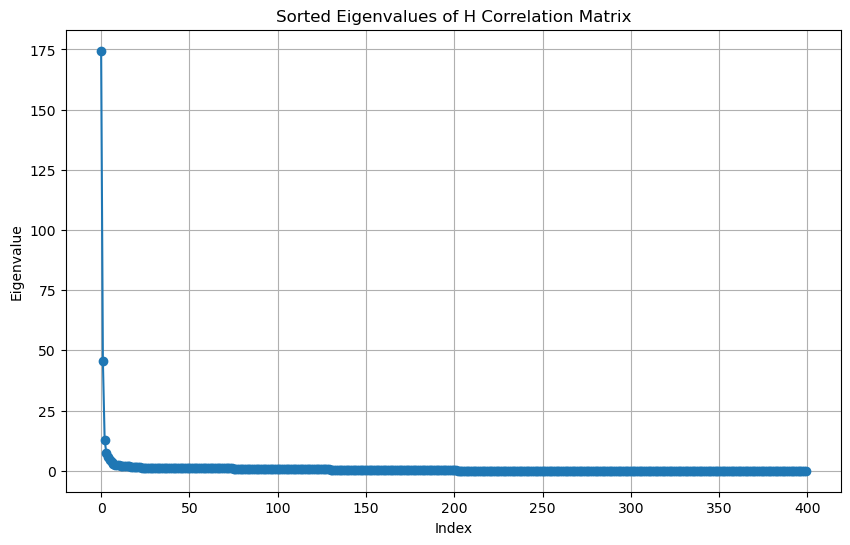

In [13]:
#Plot sorted eigenvalues
plt.figure(figsize=(10, 6))
plt.plot(H_eigenvalues, marker='o')
plt.title('Sorted Eigenvalues of H Correlation Matrix')
plt.xlabel('Index'); plt.ylabel('Eigenvalue')
plt.grid(); plt.show()

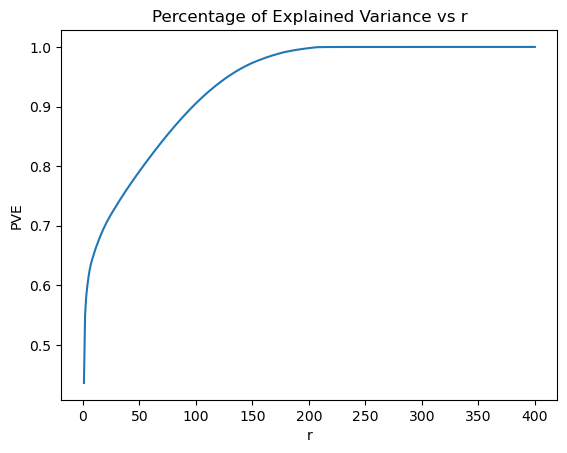

In [14]:
# Display percentage of explained variance as a curve PVE vs r
PVE = np.cumsum(H_eigenvalues) / np.sum(H_eigenvalues)
plt.plot(range(1, len(PVE)+1), PVE)
plt.xlabel("r")
plt.ylabel("PVE")
plt.title("Percentage of Explained Variance vs r")
plt.show()

In [15]:
#Compute smallest r such that PVE >= 0.95
r = np.argmax(PVE >= 0.95)
print("Smallest r such that PVE >= 0.95: ", r)
H_r = H @ H_eigenvectors[:, :r]

Smallest r such that PVE >= 0.95:  128


## Splitting dataset into training and testing sets

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import mean_squared_error

# MLP architecture: L1 = input layer ===> L2 = hidden layer ===> L3 = output layer
L1_size = H_r.shape[1]

L3_size = Y.shape[1]

# Split data into training (85%) and testing(15%) sets
X_train, X_test, Y_train, Y_test = train_test_split(H_r, Y, test_size=0.15, random_state=42)

# Standardize each feature coordinate of Y using the mean and standard deviation from the training set
Y_mean = np.mean(Y_train, axis=0)
Y_std  = np.std(Y_train, axis=0)
Y_train = (Y_train - Y_mean) / Y_std
Y_test  = (Y_test  - Y_mean) / Y_std

## Finding optimal layer size

In [ ]:
# Function to calculate the number of parameters in an MLP given the layer sizes
def num_params(L_sizes):
    num = 0
    for i in range(len(L_sizes)-1):
        weights = L_sizes[i] * L_sizes[i+1]
        thresholds = L_sizes[i+1]
        num += weights + thresholds # weights + biases
    return num

# M = 4 * size of training set
M = 4 * X_train.shape[0]
h = np.arange(1, 200)

# Find L2 size such that # parameters in MLP is closest to M
g = h[np.argmin([np.abs(num_params([L1_size, h_i, L3_size]) - M) for h_i in h])]

print("L2 size: ", g)
num_params([L1_size, g, L3_size])/M # Value should be as close to 1 as possible

L2 size:  84


np.float64(1.0007163323782235)

In [18]:
h = 2*g # Double the hidden layer size to see how it affects the number of parameters
print(num_params([L1_size, h, L3_size])/M)

2.0010744985673354


## Use scikit.learn to train your MLP when h = dim(L2)= 2 g. 
 Select the following options: initialization = random , batch size =50,  # epochs = 250,  
loss function = MSE, gradient descent algorithm = ADAM ,  
Display the root mean square  trainRMSE(m) versus  m= #epochs 
Display on the same graph the testRMSE(m) versus  m  
Display on a separate graph || gradient MSE(m) ||/ sqrt(PAR(h))

In [ ]:
from sklearn.neural_network import MLPRegressor

n_epochs = 250

MLP = MLPRegressor(
    hidden_layer_sizes=(h,),
    batch_size=50,
    solver='adam',
    loss='squared_error',
    max_iter=n_epochs)

test_RMSE = []
train_RMSE = []
grad_norms = []
for epoch in range(n_epochs):
    # Save weights before update to compute weight-change norm as gradient proxy
    if hasattr(MLP, 'coefs_'):
        prev_coefs = [c.copy() for c in MLP.coefs_]
        prev_intercepts = [b.copy() for b in MLP.intercepts_]
    else:
        prev_coefs = None

    MLP.partial_fit(X_train, Y_train) # Train MLP for one epoch on the training data

    Y_pred_train = MLP.predict(X_train) # Predict on training data to compute training RMSE
    train_RMSE.append(np.sqrt(mean_squared_error(Y_train, Y_pred_train)))

    Y_pred_test = MLP.predict(X_test) # Predict on testing data to compute testing RMSE
    test_RMSE.append(np.sqrt(mean_squared_error(Y_test, Y_pred_test)))

    # Compute weight-change norm as a proxy for gradient norm
    if prev_coefs is not None:
        delta = np.concatenate(
            [MLP.coefs_[i].flatten() - prev_coefs[i].flatten() for i in range(len(MLP.coefs_))] +
            [MLP.intercepts_[i].flatten() - prev_intercepts[i].flatten() for i in range(len(MLP.intercepts_))]
        )

        grad_norms.append(np.linalg.norm(delta))

    else:

        grad_norms.append(0.0)

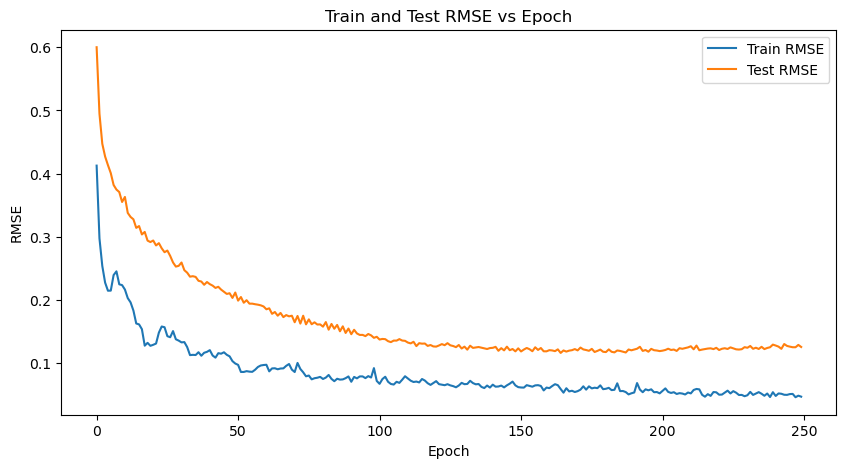

In [20]:
# Plot train and test RMSE vs epoch
fig = plt.figure(figsize=(10, 5))
plt.plot(range(n_epochs), train_RMSE, label="Train RMSE")
plt.plot(range(n_epochs), test_RMSE, label="Test RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Train and Test RMSE vs Epoch")
plt.legend()
plt.show()

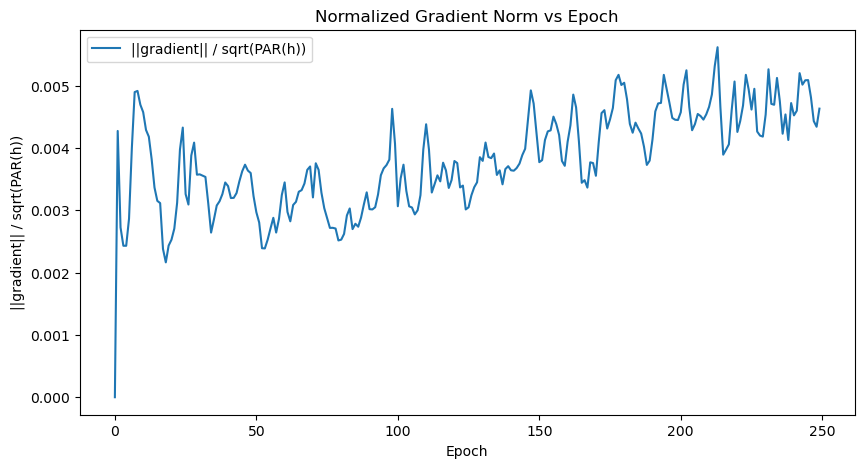

In [21]:
# Plot normalized gradient norm vs epoch
val = np.array(grad_norms) / np.sqrt(num_params([L1_size, h, L3_size]))
fig = plt.figure(figsize=(10, 5))
plt.plot(range(n_epochs), val, label="||gradient|| / sqrt(PAR(h))")
plt.xlabel("Epoch")
plt.ylabel("||gradient|| / sqrt(PAR(h))")
plt.title("Normalized Gradient Norm vs Epoch")
plt.legend()
plt.show()

## Optimal epoch and performance of MLP(2g)

In [22]:
# Choose epoch using the minimum test RMSE curve (index -> epoch number)
m = int(np.argmin(test_RMSE)) + 1
print("Optimal number of epochs:", m)

# Train a new MLP with the optimal number of epochs and evaluate its performance on the training and testing sets
MLP_2g = MLPRegressor(
    hidden_layer_sizes=(2 * g,),
    batch_size=50,
    solver='adam',
    loss='squared_error',
    max_iter=m,
    random_state=42
).fit(X_train, Y_train)

train_pred_2g = MLP_2g.predict(X_train) # Predict on training data to compute training RMSE
train_RMSE_2g = np.sqrt(mean_squared_error(Y_train, train_pred_2g)) # Compute training RMSE for the new MLP with 2g hidden layer

test_pred_2g = MLP_2g.predict(X_test) # Predict on testing data to compute testing RMSE
test_RMSE_2g = np.sqrt(mean_squared_error(Y_test, test_pred_2g)) # Compute testing RMSE for the new MLP with 2g hidden layer

print("Train RMSE for 2g hidden layer:", train_RMSE_2g)
print("Test RMSE for 2g hidden layer:", test_RMSE_2g)

Optimal number of epochs: 165
Train RMSE for 2g hidden layer: 0.09612511412246906
Test RMSE for 2g hidden layer: 0.16948683095261194


## Per-Stock Relative Errors

In [23]:
def relerr(true_raw, pred_raw, eps=1e-12):
    # Relative error per stock per sample: |true - pred| / |true|
    return np.abs(true_raw - pred_raw) / np.maximum(np.abs(true_raw), eps)

# Predictions are in standardized target units; invert to raw prices
raw_train_pred = train_pred_2g * Y_std + Y_mean
raw_test_pred = test_pred_2g * Y_std + Y_mean

# True targets are also standardized in Y_train/Y_test; invert them too
raw_train_true = Y_train * Y_std + Y_mean
raw_test_true = Y_test * Y_std + Y_mean

relerr_train = relerr(raw_train_true, raw_train_pred)
relerr_test = relerr(raw_test_true, raw_test_pred)

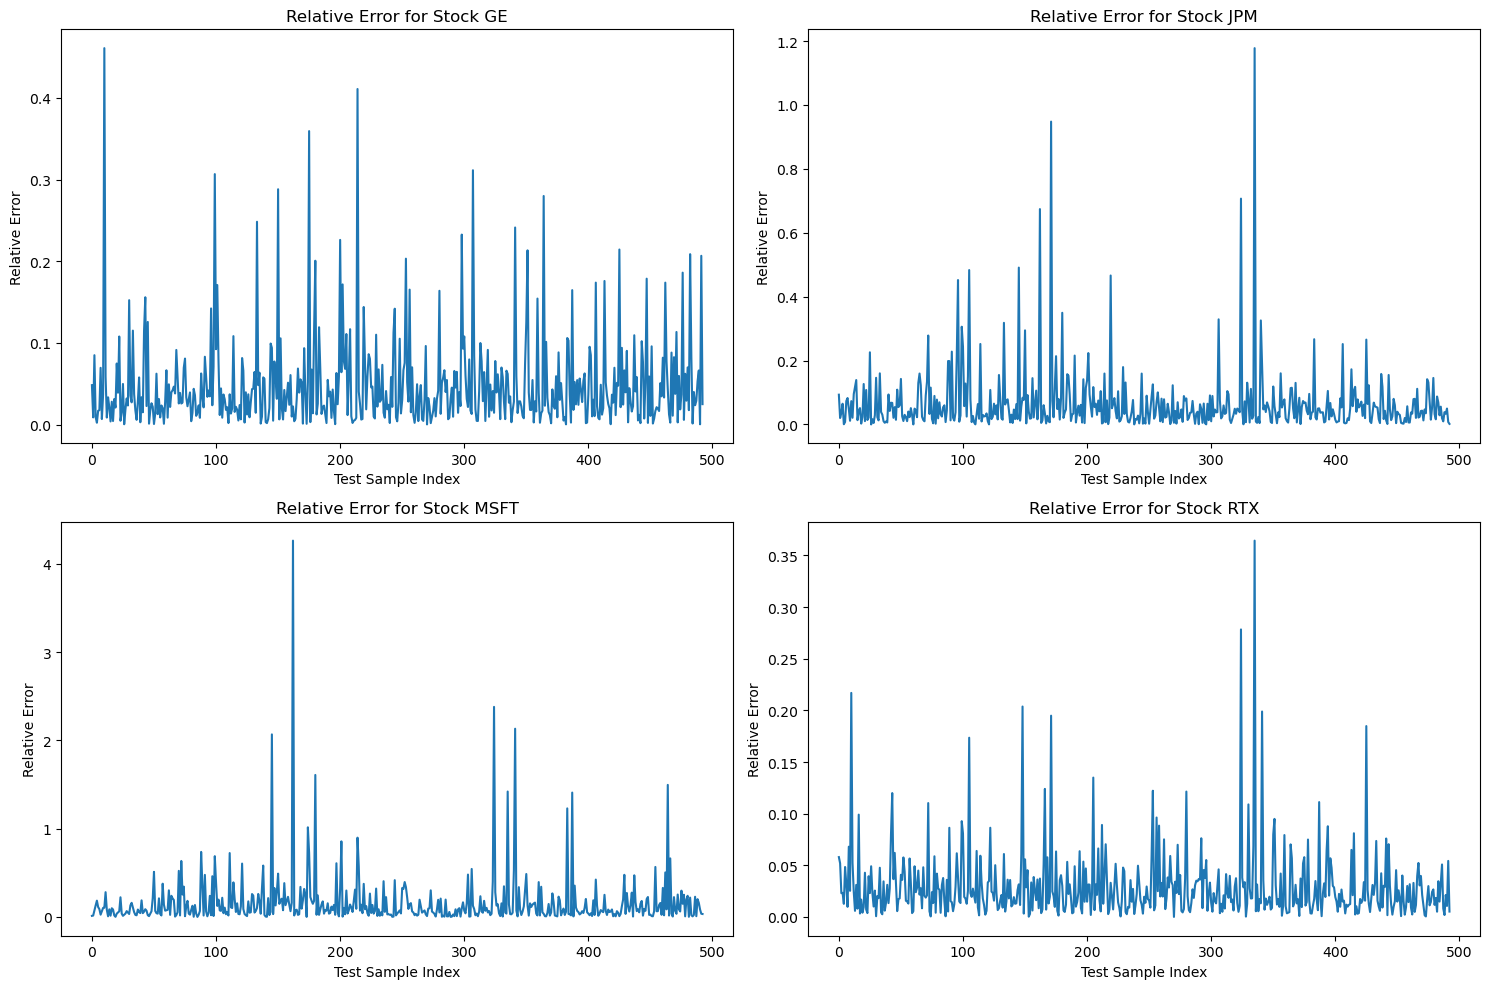

In [24]:
# Plot relative error curves for each stock on the test set
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for j in range(4):
    axs[j//2, j%2].plot(relerr_test[:, j])
    axs[j//2, j%2].set_title(f"Relative Error for Stock {Choice[j]}")
    axs[j//2, j%2].set_xlabel("Test Sample Index")
    axs[j//2, j%2].set_ylabel("Relative Error")

plt.tight_layout()
plt.show()

In [25]:
# Compute and print average relative error for each stock on training and testing sets
relerr_train_avg = np.mean(relerr_train, axis=0)
relerr_test_avg = np.mean(relerr_test, axis=0)

print(f"{'Stock':<8}{'Train Avg RelErr':>18}{'Test Avg RelErr':>18}")
for j in range(4):
    print(f"{Choice[j]:<8}{relerr_train_avg[j]:>18.6f}{relerr_test_avg[j]:>18.6f}")

Stock     Train Avg RelErr   Test Avg RelErr
GE                0.026532          0.048649
JPM               0.034742          0.065507
MSFT              0.068603          0.162940
RTX               0.016817          0.029664


## A wider network: MLP(5g)

In [26]:
# Train a new MLP with 5g hidden layer size and evaluate its performance on the training and testing sets
MLP_5g = MLPRegressor(
    hidden_layer_sizes=(5 * g,),
    batch_size=50,
    solver='adam',
    loss='squared_error',
    max_iter=m,
    random_state=42
)

MLP_5g.fit(X_train, Y_train)

train_pred_5g = MLP_5g.predict(X_train)
train_RMSE_5g = np.sqrt(mean_squared_error(Y_train, train_pred_5g))

test_pred_5g = MLP_5g.predict(X_test)
test_RMSE_5g = np.sqrt(mean_squared_error(Y_test, test_pred_5g))

print("Train RMSE for 5g hidden layer:", train_RMSE_5g)
print("Test RMSE for 5g hidden layer:", test_RMSE_5g)

Train RMSE for 5g hidden layer: 0.08772866953994597
Test RMSE for 5g hidden layer: 0.12985119083550825


## A deeper Network: (g,g)

In [27]:
# Train a new MLP with (g, g) hidden layer size and evaluate its performance on the training and testing sets
MLP_gg = MLPRegressor(
    hidden_layer_sizes=(g, g),
    batch_size=50,
    solver='adam',
    loss='squared_error',
    max_iter=m,
    random_state=42
)

MLP_gg.fit(X_train, Y_train)

train_pred_gg = MLP_gg.predict(X_train)
train_RMSE_gg = np.sqrt(mean_squared_error(Y_train, train_pred_gg))

test_pred_gg = MLP_gg.predict(X_test)
test_RMSE_gg = np.sqrt(mean_squared_error(Y_test, test_pred_gg))

print("Train RMSE for (g, g) hidden layer:", train_RMSE_gg)
print("Test RMSE for (g, g) hidden layer:", test_RMSE_gg)

Train RMSE for (g, g) hidden layer: 0.08459943121031421
Test RMSE for (g, g) hidden layer: 0.17300264174544247
